# Swap errors → `swap_errors.pdf`

One dot per session: how precise the monkey's responses were when aimed at the cued object
(**spatial error**, the circular SD of the target component) against how often it reported
the *other* object (**swap error rate**). Both come from a correct/swap/lapse von Mises
mixture fit per session — see `swap_model.py` for what the lapse term is doing there.

In [1]:
from matplotlib import pyplot as plt

import common
import swap_model

common.set_style()

FIGSIZE = (2.6, 2.7)
OUTPUT = 'swap_errors.pdf'
MARKERS = {'Perle': 'o', 'Elgar': '^'}   # the monkeys differ by shape, not colour

In [2]:
two = common.prep_2obj(common.load_ring())
sessions = swap_model.fit_sessions(two)
print(f'{len(two):,} completed 2-object trials, {len(sessions)} sessions fit')
display(sessions.round(3))

23,019 completed 2-object trials, 23 sessions fit


,subject,session,n_trials,spatial_error_deg,swap_error
0,Elgar,2022-09-06,1024,8.389,0.193
1,Elgar,2022-09-07,1005,7.405,0.220
2,Elgar,2022-09-09,1228,7.494,0.262
3,Elgar,2022-09-10,1084,7.659,0.254
4,Elgar,2022-09-11,1310,7.781,0.237
5,Elgar,2022-09-12,1075,6.856,0.272
6,Elgar,2022-09-13,1047,8.009,0.226
7,Elgar,2022-09-14,1033,6.600,0.212
8,Elgar,2022-09-15,1014,6.913,0.237
9,Elgar,2022-09-18,1020,7.047,0.180


saved swap_errors.pdf


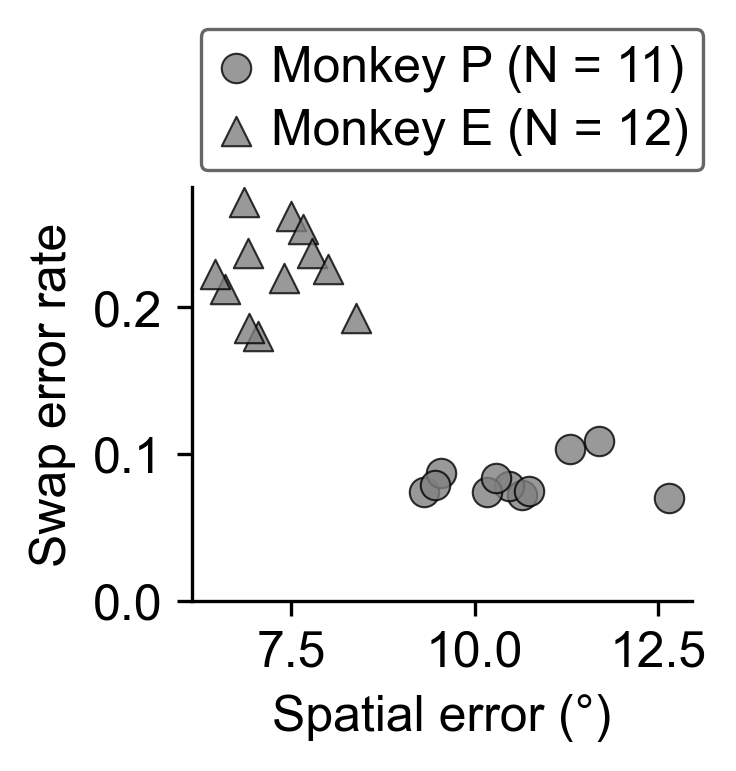

In [3]:
fig, ax = plt.subplots(figsize=FIGSIZE)
for subject in common.SUBJECTS:
    g = sessions[sessions['subject'] == subject]
    ax.scatter(g['spatial_error_deg'], g['swap_error'], s=50, alpha=0.8,
               marker=MARKERS[subject], color=(0.5, 0.5, 0.5), edgecolors='k',
               linewidths=0.5,
               label=f'{common.SUBJECT_LABELS[subject]} (N = {len(g)})')
ax.set_xlabel('Spatial error (°)')
ax.set_ylabel('Swap error rate')
ax.set_ylim(bottom=0)
common.despine(ax)

# The entries carry each monkey's N, which makes them too wide to sit in a corner without
# covering data — so the legend goes above the axes, where its width costs nothing.
handles, labels = ax.get_legend_handles_labels()
common.boxed_legend(ax, handles, labels, ncol=1, loc='lower center',
                    bbox_to_anchor=(0.52, 1.04), borderaxespad=0.0, labelspacing=0.3)
fig.tight_layout()
common.save(fig, OUTPUT)
plt.show()